# Практическая работа №4

## Регрессионная модель — Вариант B

**Датасет:** Palmer Penguins

**Цель работы:** обучить линейную регрессию для предсказания массы тела пингвинов, проверить мультиколлинеарность, сравнить два набора признаков и оценить качество моделей.

**Целевая переменная:** body_mass_g — масса тела пингвина в граммах.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
df = pd.read_csv("../data/penguins.csv")

display(df.head())

print("Размер датасета:", df.shape)

print("\nПропущенные значения:")
print(df.isnull().sum())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


Размер датасета: (344, 7)

Пропущенные значения:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


### Первичный анализ данных

В работе используется датасет Palmer Penguins, который содержит информацию о физических характеристиках пингвинов.

Для задачи регрессии выбрана числовая целевая переменная body_mass_g — масса тела в граммах.

В некоторых признаках присутствуют пропущенные значения. Для их обработки будет применена медиана, вычисленная только на обучающей выборке.

In [3]:
features_all = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm"
]

target = "body_mass_g"

# Убираем строки без известной целевой переменной
data = df.dropna(subset=[target]).copy()

X = data[features_all]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (273, 3)
Test: (69, 3)


### Разделение данных

Для предсказания массы тела выбраны три числовых признака: длина клюва, глубина клюва и длина ласты.

Строки с отсутствующей целевой переменной body_mass_g исключены.

Данные разделены на 80% для обучения и 20% для тестирования.

Обработка пропусков и масштабирование будут обучаться только на тренировочной выборке, что предотвращает утечку данных.

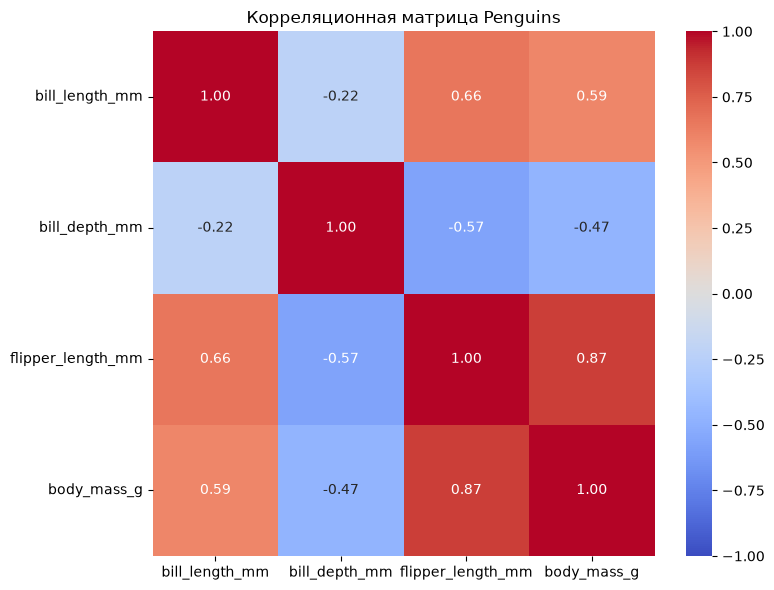

In [4]:
train_data = X_train.copy()
train_data["body_mass_g"] = y_train

corr = train_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Корреляционная матрица Penguins")
plt.tight_layout()
plt.show()

In [5]:
feature_corr = X_train.corr().abs()

upper = feature_corr.where(
    np.triu(
        np.ones(feature_corr.shape),
        k=1
    ).astype(bool)
)

print("Корреляции между признаками:")
display(upper)

Корреляции между признаками:


,bill_length_mm,bill_depth_mm,flipper_length_mm
bill_length_mm,NaN,0.223038,0.658329
bill_depth_mm,NaN,NaN,0.573100
flipper_length_mm,NaN,NaN,NaN


### Анализ мультиколлинеарности

Корреляционная матрица позволяет определить линейные связи между признаками.

Особенно важно проверить, насколько сильно связаны физические характеристики пингвинов.

Высокая корреляция между двумя признаками может указывать на мультиколлинеарность и затруднять интерпретацию коэффициентов линейной регрессии.

Поэтому далее будет проверена модель с сокращённым набором признаков.

In [6]:
def create_model():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regression", LinearRegression())
    ])

model_all = create_model()

model_all.fit(X_train, y_train)

pred_all = model_all.predict(X_test)

print("Первая модель обучена!")

Первая модель обучена!


### Первая модель — все признаки

Обучена линейная регрессия с использованием трёх числовых признаков.

Перед обучением пропущенные значения заполняются медианой, после чего применяется StandardScaler.

Все шаги объединены в Pipeline. Это позволяет использовать статистики только тренировочной выборки.

In [7]:
mae_all = mean_absolute_error(y_test, pred_all)
mse_all = mean_squared_error(y_test, pred_all)
rmse_all = np.sqrt(mse_all)
r2_all = r2_score(y_test, pred_all)

print("MAE:", round(mae_all, 2), "г")
print("MSE:", round(mse_all, 2), "г²")
print("RMSE:", round(rmse_all, 2), "г")
print("R²:", round(r2_all, 3))

MAE: 310.55 г
MSE: 141108.52 г²
RMSE: 375.64 г
R²: 0.788


### Оценка первой модели

Качество линейной регрессии оценивается по MAE, MSE, RMSE и R².

MAE показывает среднюю абсолютную ошибку предсказания массы тела в граммах.

RMSE также измеряется в граммах, но сильнее учитывает большие ошибки.

R² показывает, насколько хорошо модель объясняет изменение массы тела относительно базового прогноза средним значением.

In [8]:
features_reduced = [
    "bill_length_mm",
    "flipper_length_mm"
]

model_reduced = create_model()

model_reduced.fit(
    X_train[features_reduced],
    y_train
)

pred_reduced = model_reduced.predict(
    X_test[features_reduced]
)

print("Вторая модель обучена!")

Вторая модель обучена!


### Вторая модель — сокращённый набор

Во второй модели используются длина клюва и длина ласты.

Признак bill_depth_mm исключён в рамках эксперимента по сокращению набора признаков.

Цель эксперимента — проверить, насколько меняется точность прогноза при использовании более простой модели.

In [9]:
results = pd.DataFrame({
    "Model": [
        "All features",
        "Reduced features"
    ],
    "MAE": [
        mean_absolute_error(y_test, pred_all),
        mean_absolute_error(y_test, pred_reduced)
    ],
    "MSE": [
        mean_squared_error(y_test, pred_all),
        mean_squared_error(y_test, pred_reduced)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, pred_all)),
        np.sqrt(mean_squared_error(y_test, pred_reduced))
    ],
    "R2": [
        r2_score(y_test, pred_all),
        r2_score(y_test, pred_reduced)
    ]
})

display(results.round(3))

,Model,MAE,MSE,RMSE,R2
0,All features,310.547,141108.516,375.644,0.788
1,Reduced features,313.606,143726.904,379.113,0.784


### Сравнение моделей

Две модели сравниваются на одной и той же тестовой выборке.

Для оценки используются MAE, MSE, RMSE и R².

Меньшие значения MAE и RMSE означают меньшую ошибку предсказания. Более высокое значение R² обычно указывает на лучшее соответствие модели данным.

Если сокращённая модель показывает сопоставимое качество, её можно рассматривать как более простой вариант.

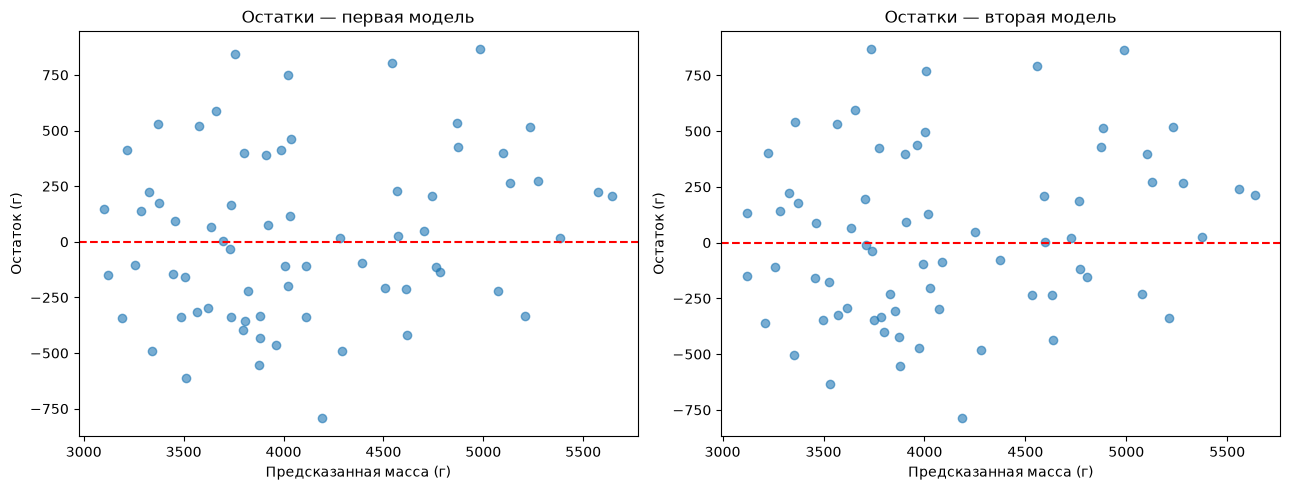

In [10]:
residuals_all = y_test - pred_all
residuals_reduced = y_test - pred_reduced

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    pred_all,
    residuals_all,
    alpha=0.6
)

axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Остатки — первая модель")
axes[0].set_xlabel("Предсказанная масса (г)")
axes[0].set_ylabel("Остаток (г)")

axes[1].scatter(
    pred_reduced,
    residuals_reduced,
    alpha=0.6
)

axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Остатки — вторая модель")
axes[1].set_xlabel("Предсказанная масса (г)")
axes[1].set_ylabel("Остаток (г)")

plt.tight_layout()
plt.show()

### Анализ остатков

Графики показывают ошибки предсказаний обеих моделей.

В идеале остатки должны располагаться без выраженного систематического паттерна вокруг горизонтальной линии нуля.

Если заметна кривая, наклон или изменение ширины разброса, это может указывать на ограничения линейной регрессии.

Окончательный вывод о паттерне следует сделать после просмотра полученных графиков.

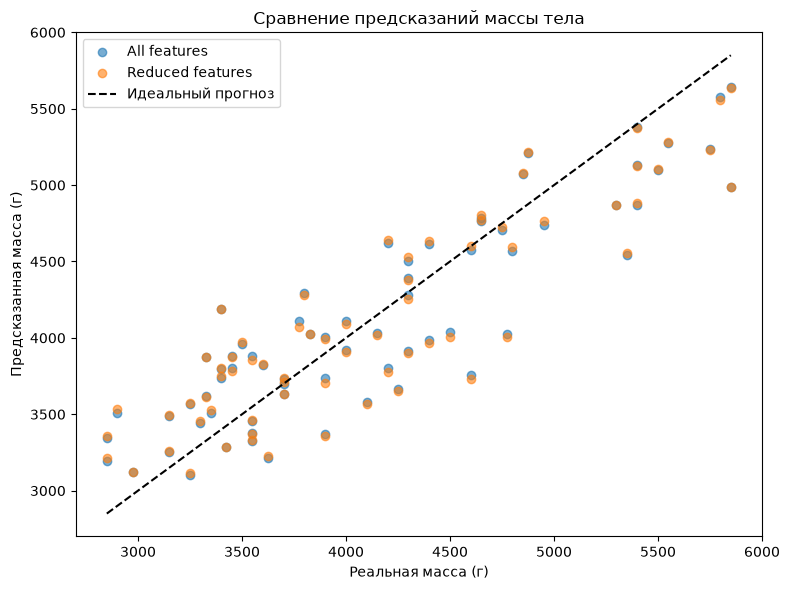

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    pred_all,
    alpha=0.6,
    label="All features"
)

plt.scatter(
    y_test,
    pred_reduced,
    alpha=0.6,
    label="Reduced features"
)

limits = [
    min(y_test.min(), pred_all.min(), pred_reduced.min()),
    max(y_test.max(), pred_all.max(), pred_reduced.max())
]

plt.plot(limits, limits, "k--", label="Идеальный прогноз")

plt.title("Сравнение предсказаний массы тела")
plt.xlabel("Реальная масса (г)")
plt.ylabel("Предсказанная масса (г)")
plt.legend()
plt.tight_layout()
plt.show()

### Анализ предсказаний

На графике сравниваются реальные и предсказанные значения массы тела пингвинов.

Пунктирная линия соответствует идеальному прогнозу.

Чем ближе точки к диагонали, тем меньше ошибка модели. Большие отклонения показывают менее точные предсказания.

In [12]:
coef_table = pd.DataFrame({
    "Feature": features_all,
    "Coefficient": model_all.named_steps[
        "regression"
    ].coef_
})

coef_table["Absolute"] = coef_table["Coefficient"].abs()

display(
    coef_table.sort_values(
        "Absolute",
        ascending=False
    )
)

,Feature,Coefficient,Absolute
2,flipper_length_mm,688.231176,688.231176
0,bill_length_mm,22.171924,22.171924
1,bill_depth_mm,21.621254,21.621254


### Анализ коэффициентов

Коэффициенты линейной регрессии показывают направление и величину связи признаков с прогнозируемой массой тела.

Поскольку использовался StandardScaler, коэффициенты относятся к стандартизированным признакам.

Больший по модулю коэффициент показывает более сильное влияние признака на линейный прогноз при фиксированных остальных признаках, но не доказывает причинно-следственную связь.

## Итоговый отчёт

1. В практической работе использован датасет Palmer Penguins. Целью регрессии является предсказание массы тела пингвина в граммах.

2. Данные разделены на обучающую и тестовую выборки в соотношении 80/20.

3. Для предобработки использован Pipeline с SimpleImputer и StandardScaler. Статистики вычисляются только на тренировочной выборке.

4. Проведён анализ корреляций между числовыми признаками и проверена возможная мультиколлинеарность.

5. Обучены две модели LinearRegression: на полном и сокращённом наборах признаков.

6. Качество моделей сравнивается по MAE, MSE, RMSE и R². MAE и RMSE интерпретируются в граммах.

7. Построены графики остатков и сравнения предсказанных значений с реальными.

### Заключение

Линейная регрессия позволяет прогнозировать массу тела пингвинов по измерениям их физических характеристик.

Сравнение моделей помогает проверить, насколько необходим каждый признак и можно ли использовать более простой набор без существенного ухудшения качества.

Окончательный выбор модели должен опираться на полученные метрики и анализ остатков.